In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [19]:
#  Load Data

data = pd.read_csv('advertising.csv')

In [20]:
data

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [21]:

print("Missing Values:\n", data.isnull().sum())

Missing Values:
 TV           0
radio        0
newspaper    0
sales        0
dtype: int64


In [22]:
# Features & Target

X = data[['TV', 'radio', 'newspaper']]
y = data['sales']


In [23]:
from sklearn.model_selection import train_test_split

# Split first
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [24]:

# Scaling 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [25]:

#  Evaluation Function

from sklearn.metrics import mean_squared_error, r2_score

def evaluate(model_name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{model_name:<20} | RMSE: {rmse:.3f} | R²: {r2:.3f}")
    return rmse, r2


In [26]:

#  Linear Regression

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)



In [27]:

#  Lasso & Ridge 

from sklearn.linear_model import Lasso, Ridge

lasso = Lasso(alpha=0.11)
ridge = Ridge(alpha=0.01)

lasso.fit(X_train, y_train)
ridge.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)
y_pred_ridge = ridge.predict(X_test)



In [28]:

#  Evaluation

print("\n--- Model Performance ---")
evaluate("Linear Regression", y_test, y_pred_lr)
evaluate("Lasso Regression", y_test, y_pred_lasso)
evaluate("Ridge Regression", y_test, y_pred_ridge)



--- Model Performance ---
Linear Regression    | RMSE: 1.949 | R²: 0.861
Lasso Regression     | RMSE: 1.921 | R²: 0.865
Ridge Regression     | RMSE: 1.949 | R²: 0.861


(np.float64(1.9485430609855268), 0.8609458149275224)

In [29]:
#  Coefficients

features = ['TV', 'Radio', 'Newspaper']

print("\n--- Coefficients ---")
print("Linear :", dict(zip(features, lr.coef_)))
print("Lasso  :", dict(zip(features, lasso.coef_)))
print("Ridge  :", dict(zip(features, ridge.coef_)))




--- Coefficients ---
Linear : {'TV': np.float64(3.6833407810865872), 'Radio': np.float64(2.9062524207719322), 'Newspaper': np.float64(0.14194771902905456)}
Lasso  : {'TV': np.float64(3.58098477680561), 'Radio': np.float64(2.830632000232782), 'Newspaper': np.float64(0.06117041731187287)}
Ridge  : {'TV': np.float64(3.6830895365463996), 'Radio': np.float64(2.906036884519088), 'Newspaper': np.float64(0.14201952493846873)}


In [30]:
#  Cross-Validation (Best Alpha)

from sklearn.linear_model import LassoCV, RidgeCV

alphas = np.linspace(0.01, 10, 100)

lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)
ridge_cv = RidgeCV(alphas=alphas, cv=5)

lasso_cv.fit(X_train, y_train)
ridge_cv.fit(X_train, y_train)

print("\n--- Best Alphas ---")
print("LassoCV Alpha:", lasso_cv.alpha_)
print("RidgeCV Alpha:", ridge_cv.alpha_)

# Predictions
y_pred_lasso_cv = lasso_cv.predict(X_test)
y_pred_ridge_cv = ridge_cv.predict(X_test)

print("\n--- Tuned Model Performance ---")
evaluate("LassoCV", y_test, y_pred_lasso_cv)
evaluate("RidgeCV", y_test, y_pred_ridge_cv)



--- Best Alphas ---
LassoCV Alpha: 0.01
RidgeCV Alpha: 0.01

--- Tuned Model Performance ---
LassoCV              | RMSE: 1.945 | R²: 0.861
RidgeCV              | RMSE: 1.949 | R²: 0.861


(np.float64(1.9485430609855268), 0.8609458149275224)

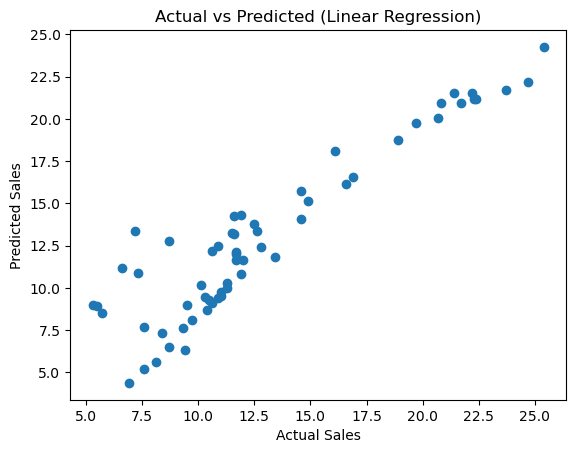

In [31]:
# Actual vs Predicted Plot
plt.figure()
plt.scatter(y_test, y_pred_lr)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted (Linear Regression)")
plt.show()

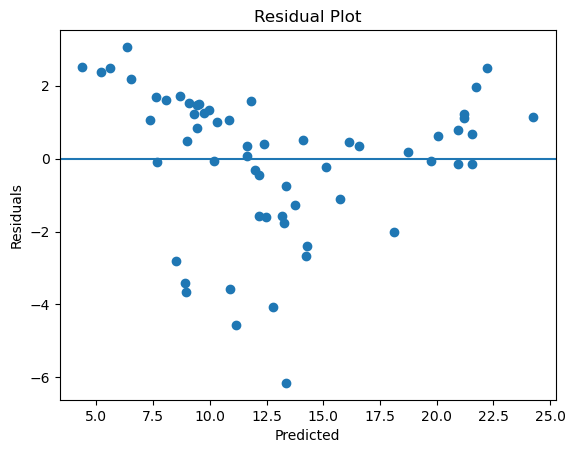

In [32]:

#  Residual Plot
residuals = y_test - y_pred_lr
plt.figure()
plt.scatter(y_pred_lr, residuals)
plt.axhline(0)
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


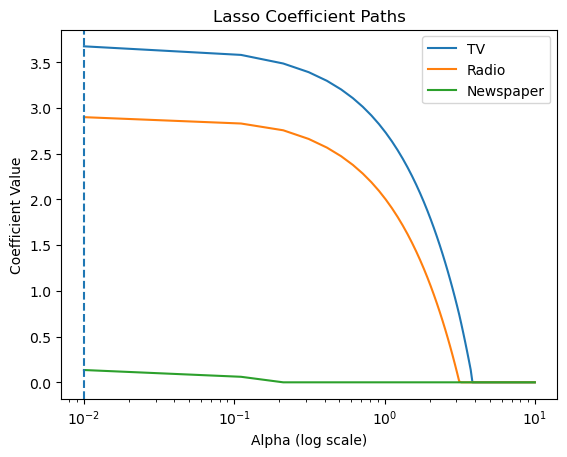

In [33]:
#  Lasso Coefficient Path

# This graph shows how Lasso removes less important features as we increase alpha.

from sklearn.linear_model import lasso_path

alphas_lasso, coefs_lasso, _ = lasso_path(X_train, y_train, alphas=alphas)

plt.figure()

for i, coef in enumerate(coefs_lasso):
    plt.plot(alphas_lasso, coef, label=features[i])

plt.xscale('log')
plt.axvline(lasso_cv.alpha_, linestyle='--')
plt.xlabel("Alpha (log scale)")
plt.ylabel("Coefficient Value")
plt.title("Lasso Coefficient Paths")
plt.legend()
plt.show()


In [34]:

#  ElasticNet 

from sklearn.linear_model import ElasticNetCV

elastic = ElasticNetCV(cv=5)
elastic.fit(X_train, y_train)

y_pred_elastic = elastic.predict(X_test)

print("\n--- ElasticNet ---")
print("Best Alpha:", elastic.alpha_)
evaluate("ElasticNet", y_test, y_pred_elastic)


--- ElasticNet ---
Best Alpha: 0.00775935269139972
ElasticNet           | RMSE: 1.948 | R²: 0.861


(np.float64(1.947706419804813), 0.8610652000044358)